# Discrete and smeared stringers: cylinders with riveted Z stringers (Peterson and Dow 1959; Card and Jones 1966)

Peterson and Dow [1] tested in axial compression 7075-T6 cylinders stiffened
by Z-section stringers riveted inside the skin, 1.25 in apart. Card and Jones
[2] tested the same cylinders with the stringers outside and list both
series in their Table I (p. 7): cylinders 5, 7, 9, 11 (external, [2]) and 6,
8, 10, 12 (internal, [1]), with the test loads and the loads of their
smeared-stiffener theory for clamped ($\bar{N}_c$) and simply supported
($\bar{N}_s$) ends. This notebook models the cylinders with discrete
stringers and compares with these values, to quantify the gap between
discrete and smeared stringers at the spacing of 1.25 in (the integral blade
cylinders 1 to 4 of [2], 1.0 in apart, are in the notebook
`card1966_stiffened_cylinder_buckling.ipynb`).

The model of this repository represents a stringer by one plate strip normal
to the skin (a blade). A Z section cannot be represented exactly by one
strip; instead two equivalent blades are used, and both the discrete model
and the smeared theory are evaluated for each, so that the discreteness gap
(discrete model against the smeared theory of the same blade) is separated
from the effect of replacing the Z by a blade (the smeared theory for the
blade against the smeared theory for the Z, which reproduces $\bar{N}_c$ and
$\bar{N}_s$ of [2]).

[1] J. P. Peterson and M. B. Dow, *Compression tests on circular cylinders
stiffened longitudinally by closely spaced Z-section stringers*, NASA Memo
2-12-59L, March 1959.

[2] M. F. Card and R. M. Jones, *Experimental and theoretical results for
buckling of eccentrically stiffened cylinders*, NASA TN D-3639, October 1966,
https://ntrs.nasa.gov/citations/19660027866.

[3] D. L. Block, M. F. Card and M. M. Mikulas, Jr., *Buckling of eccentrically
stiffened orthotropic cylinders*, NASA TN D-2960, 1965,
https://ntrs.nasa.gov/citations/19650021133.

In [1]:
%matplotlib inline
import time

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from scipy.optimize import brentq

from bfsccylinder.version import __version__ as bfsccylinder_version
from bfscplate2d.version import __version__ as bfscplate2d_version
from blade_cylinder_sector import (BladeCylinderSector, buckling_membrane,
                                   axial_nodes, normalize_phase, W)
from smeared_stiffened_cylinder import buckling_ss, buckling_ritz, minimum

print('bfsccylinder', bfsccylinder_version)
print('bfscplate2d', bfscplate2d_version)


def pct(value, ref):
    return 100*(value/ref - 1)


def table(header, rows):
    out = ['| ' + ' | '.join(header) + ' |', '|' + '---|'*len(header)]
    out += ['| ' + ' | '.join(str(c) for c in row) + ' |' for row in rows]
    display(Markdown('\n'.join(out)))

bfsccylinder 0.7.1
bfscplate2d 0.5.0


## Cylinders, geometry and material

Table I(a) of [2] (p. 7): skin thickness $t$, length $L$, radius $R = 15.92$
in, measured area $A_t$, test load $\bar{P}_e$, circumferential waves $n_e$,
and $\bar{N}_e$, $\bar{N}_c$, $\bar{N}_s$ (headed kips/in., in lb/in:
$\bar{P}_e/(2\pi R)$ gives $\bar{N}_e$ in lb/in). $E = 10.5 \times 10^3$ ksi,
$\mu = 0.32$ (footnote). Stringer spacing 1.25 in (Fig. 2(a)), that is
$2\pi R/1.25 = 80.0$: 80 stringers. The ends were ground flat and loaded
between the platens (p. 6 of [2], p. 4 of [1]): clamped. In [1] (Table I,
p. 11) the same cylinders have $R = 15.80$ in and $E = 10\,900$ ksi (p. 4);
Card and Jones' values use $R = 15.92$ in and $E = 10\,500$ ksi, which are
used here. Correspondence: cylinders 6, 8, 10, 12 of [2] are 6, 5, 3, 4 of [1].

In [2]:
E = 10.5e6   # psi
mu = 0.32
R = 15.92    # in
NS = 80
d = 2*np.pi*R/NS
# Table I(a) of [2], p. 7: side, t, L (in), A_t (in^2), P_e (kips), n_e, N_e, N_c, N_s (lb/in)
CYL = {5: ('external', .0410, 59.00, 7.15, 169.6, 5, 1696, 2289, 1193),
       6: ('internal', .0401, 59.00, 7.25, 99.5, 6, 995, 1174, 766),
       7: ('external', .0391, 41.83, 7.02, 186.3, 7, 1863, 2617, 1283),
       8: ('internal', .0401, 41.83, 7.31, 126.0, 6, 1260, 1383, 773),
       9: ('external', .0392, 29.68, 7.06, 273.0, 7, 2730, 3426, 1574),
       10: ('internal', .0403, 29.68, 7.21, 171.0, 7, 1710, 1813, 838),
       11: ('external', .0395, 20.77, 7.18, 378.0, 8, 3780, 4947, 2068),
       12: ('internal', .0401, 20.77, 7.18, 273.0, 8, 2730, 2845, 1027)}
PETERSON = {6: 6, 8: 5, 10: 3, 12: 4}  # cylinder of [2]: specimen of [1]
print('stringer spacing %.4f in' % d)
rows = []
for c, (side, t, L, At, Pe, ne, Ne, Nc, Ns) in CYL.items():
    rows.append([c, PETERSON.get(c, '-'), side, t, L, At, Pe, ne,
                 '%.0f (%d)' % (Pe*1e3/(2*np.pi*R), Ne), Nc, Ns])
table(['cyl. [2]', 'specimen [1]', 'stringers', 't, in', 'L, in', 'A_t, in^2', 'P_e, kips',
       'n_e', 'P_e/(2 pi R), lb/in (N_e)', 'N_c', 'N_s'], rows)

stringer spacing 1.2504 in


| cyl. [2] | specimen [1] | stringers | t, in | L, in | A_t, in^2 | P_e, kips | n_e | P_e/(2 pi R), lb/in (N_e) | N_c | N_s |
|---|---|---|---|---|---|---|---|---|---|---|
| 5 | - | external | 0.041 | 59.0 | 7.15 | 169.6 | 5 | 1696 (1696) | 2289 | 1193 |
| 6 | 6 | internal | 0.0401 | 59.0 | 7.25 | 99.5 | 6 | 995 (995) | 1174 | 766 |
| 7 | - | external | 0.0391 | 41.83 | 7.02 | 186.3 | 7 | 1862 (1863) | 2617 | 1283 |
| 8 | 5 | internal | 0.0401 | 41.83 | 7.31 | 126.0 | 6 | 1260 (1260) | 1383 | 773 |
| 9 | - | external | 0.0392 | 29.68 | 7.06 | 273.0 | 7 | 2729 (2730) | 3426 | 1574 |
| 10 | 3 | internal | 0.0403 | 29.68 | 7.21 | 171.0 | 7 | 1710 (1710) | 1813 | 838 |
| 11 | - | external | 0.0395 | 20.77 | 7.18 | 378.0 | 8 | 3779 (3780) | 4947 | 2068 |
| 12 | 4 | internal | 0.0401 | 20.77 | 7.18 | 273.0 | 8 | 2729 (2730) | 2845 | 1027 |

## The Z section

Fig. 2(a) of [2] (p. 6) and Fig. 2(b) of [1] (p. 12): formed sheet 0.040 in
thick, bend radius 0.04 in, depth 0.54 in from the skin surface to the outer
face of the free flange, attached flange 0.375 in ([1]: 0.38 in) and free
flange 0.22 in, both overall from the face of the web, 3/32-in rivets at
5/16 in pitch, 0.19 in from the web. "All dimensions are nominal except
$A_t$" ([2], p. 5). Two readings: square corners (three rectangles), and the
centre line of the sheet with the two bends of inner radius 0.04 in (thin
walls). The table gives the section and $A_t$ computed with it (skin, 80
stringers; the three lap joints of [2], 3/4 in wide, are left out) and the
smeared theory of [3] with each reading: equation (15) (simply supported,
`buckling_ss`, minimum over $m \le 12$, $n \le 40$) and the Galerkin solution
of [2] for clamped ends (`buckling_ritz`, 16 terms, minimum over $n$),
against $\bar{N}_s$ and $\bar{N}_c$; $J = \sum b t^3/3$.

In [3]:
TZ, RB, HZ, BB, BT = 0.040, 0.04, 0.54, 0.375, 0.22


def z_section(t, side, bends):
    # centre line of the Z, z from the skin surface: list of (length, z)
    # pieces; area, centroid, moment of inertia about the centroid, J
    pieces = []
    zb, zt = TZ/2, HZ - TZ/2
    if bends:
        rc = RB + TZ/2
        pieces.append((BB - TZ/2 - rc, zb))
        for a in np.linspace(0, np.pi/2, 41)[:-1] + np.pi/160:
            pieces.append((rc*np.pi/80, zb + rc - rc*np.cos(a)))
        lw = zt - zb - 2*rc
        k = 40
        for z in zb + rc + (np.arange(k) + 0.5)*lw/k:
            pieces.append((lw/k, z))
        for a in np.linspace(0, np.pi/2, 41)[:-1] + np.pi/160:
            pieces.append((rc*np.pi/80, zt - rc + rc*np.sin(a)))
        pieces.append((BT - TZ/2 - rc, zt))
        ds = np.array([p[0] for p in pieces])
        z = np.array([p[1] for p in pieces])
        A = TZ*ds.sum()
        zc = (TZ*ds*z).sum()/A
        Ic = (TZ*ds*(z - zc)**2).sum() + TZ**3/12*(BB + BT)
        J = ds.sum()*TZ**3/3
    else:
        rects = [(BB, TZ, 0.), (TZ, HZ - 2*TZ, TZ), (BT, TZ, HZ - TZ)]
        A = sum(w*h for w, h, z0 in rects)
        zc = sum(w*h*(z0 + h/2) for w, h, z0 in rects)/A
        Ic = sum(w*h**3/12 + w*h*(z0 + h/2 - zc)**2 for w, h, z0 in rects)
        J = sum(max(w, h)*min(w, h)**3/3 for w, h, z0 in rects)
    sign = 1. if side == 'external' else -1.
    z = sign*(t/2 + zc)
    return dict(A=A, zc=zc, z=z, Ic=Ic, Io=Ic + A*z**2, J=J)


mgrid = np.arange(1, 13)[:, None]
ngrid = np.arange(1, 41)[None, :]


def smeared_ss(t, L, s):
    N = buckling_ss(R, L, t, E, mu, d, s['A'], s['z'], s['Io'], s['J'], mgrid, ngrid)
    i, j = np.unravel_index(np.argmin(N), N.shape)
    return N[i, j], (int(mgrid[i, 0]), int(ngrid[0, j]))


def smeared_cc(t, L, s):
    return minimum(lambda n: buckling_ritz(R, L, t, E, mu, d, s['A'], s['z'], s['Io'],
                                           s['J'], n, 'CC', 16)[0], range(2, 31))


rows = []
SM = {}
for bends in (False, True):
    s = z_section(0.04, 'external', bends)
    print('%s: A = %.5f in^2, centroid %.4f in above the skin, I_c = %.4e in^4, J = %.3e in^4'
          % ('bends' if bends else 'square corners', s['A'], s['zc'], s['Ic'], s['J']))
for c, (side, t, L, At, Pe, ne, Ne, Nc, Ns) in CYL.items():
    row = [c, side]
    for bends in (False, True):
        s = z_section(t, side, bends)
        Nss, mn = smeared_ss(t, L, s)
        Ncc, n = smeared_cc(t, L, s)
        SM[(c, bends)] = (Ncc, n, Nss, mn)
        row += ['%+.1f %%' % pct(2*np.pi*R*t + NS*s['A'], At),
                '%.0f (n = %d), %+.1f %%' % (Ncc, n, pct(Ncc, Nc)),
                '%.0f %s, %+.1f %%' % (Nss, mn, pct(Nss, Ns))]
    rows.append(row)
table(['cyl.', 'stringers', 'square: A_t', 'square: CC vs N_c', 'square: SS vs N_s',
       'bends: A_t', 'bends: CC vs N_c', 'bends: SS vs N_s'], rows)

square corners: A = 0.04220 in^2, centroid 0.2333 in above the skin, I_c = 1.7582e-03 in^4, J = 2.251e-05 in^4
bends: A = 0.04014 in^2, centroid 0.2314 in above the skin, I_c = 1.6088e-03 in^4, J = 2.141e-05 in^4


| cyl. | stringers | square: A_t | square: CC vs N_c | square: SS vs N_s | bends: A_t | bends: CC vs N_c | bends: SS vs N_s |
|---|---|---|---|---|---|---|---|
| 5 | external | +4.6 % | 2350 (n = 7), +2.7 % | 1220 (1, 6), +2.2 % | +2.3 % | 2281 (n = 7), -0.3 % | 1193 (1, 6), -0.0 % |
| 6 | internal | +1.9 % | 1201 (n = 8), +2.3 % | 769 (1, 6), +0.4 % | -0.4 % | 1169 (n = 8), -0.4 % | 765 (1, 6), -0.2 % |
| 7 | external | +3.8 % | 2702 (n = 9), +3.3 % | 1319 (1, 7), +2.8 % | +1.5 % | 2608 (n = 9), -0.4 % | 1281 (1, 7), -0.1 % |
| 8 | internal | +1.1 % | 1411 (n = 8), +2.0 % | 780 (1, 7), +0.9 % | -1.2 % | 1379 (n = 8), -0.3 % | 772 (1, 7), -0.1 % |
| 9 | external | +3.4 % | 3568 (n = 10), +4.1 % | 1624 (1, 9), +3.2 % | +1.0 % | 3417 (n = 10), -0.3 % | 1572 (1, 9), -0.1 % |
| 10 | internal | +2.7 % | 1877 (n = 9), +3.5 % | 851 (1, 8), +1.6 % | +0.4 % | 1808 (n = 9), -0.3 % | 836 (1, 8), -0.2 % |
| 11 | external | +2.0 % | 5194 (n = 11), +5.0 % | 2155 (1, 10), +4.2 % | -0.2 % | 4940 (n = 11), -0.1 % | 2066 (1, 10), -0.1 % |
| 12 | internal | +2.9 % | 2985 (n = 10), +4.9 % | 1060 (1, 9), +3.2 % | +0.6 % | 2834 (n = 10), -0.4 % | 1025 (1, 9), -0.2 % |

The reading with the bends reproduces $\bar{N}_c$ and $\bar{N}_s$ of [2] more
closely and is the Z section used below. Card and Jones do not print the
section properties they used; the remaining differences (above 1 % for the
shorter cylinders) are not explained by these two readings.

## Equivalent blades

A blade of thickness $t_b$ and height $h_b$ standing on the skin has two
parameters, so it can match two of the properties of the Z. Two blades:

- **blade A-z**: same area $A$ and same centroid ($h_b = 2 z_c$, $t_b =
  A/h_b$);
- **blade A-Io**: same area and same moment of inertia $I_o$ about the middle
  surface of the skin (the bending stiffness of the stringer with its
  eccentricity).

In the discrete model the blade is the plate strip from the middle surface of
the skin to its tip, of width $H_s = h_b + t/2$, with $D_{66}$ scaled so that
its twisting stiffness $4 D_{66} H_s$ equals $G J$ of the Z. The smeared
theory of the strip as modelled ($A = t_b H_s$, $\bar{z} = \pm H_s/2$, $I_o
= t_b H_s^3/3$, $J$ of the Z) is the reference of the discreteness gap.

In [4]:
def blades(t, side):
    z = z_section(t, side, True)
    sign = 1. if side == 'external' else -1.
    out = {}
    hb = 2*z['zc']
    out['A-z'] = (z['A']/hb, hb)
    f = lambda hb: (z['A']/hb*hb**3/12 + z['A']*((t + hb)/2)**2) - z['Io']
    hb = brentq(f, 0.05, 2.)
    out['A-Io'] = (z['A']/hb, hb)
    strips = {}
    for k, (tb, hb) in out.items():
        Hs = hb + t/2
        strips[k] = dict(tb=tb, hb=hb, Hs=Hs, A=tb*Hs, z=sign*Hs/2, Io=tb*Hs**3/3,
                         J=z['J'], Jplate=Hs*tb**3/3)
    return strips


rows = []
STRIPS = {}
for c, (side, t, L, At, Pe, ne, Ne, Nc, Ns) in CYL.items():
    STRIPS[c] = blades(t, side)
    zc_cc, _, zc_ss, _ = SM[(c, True)]
    for k, s in STRIPS[c].items():
        Ncc, n = smeared_cc(t, L, s)
        Nss, mn = smeared_ss(t, L, s)
        s['sm'] = (Ncc, n, Nss, mn)
        rows.append([c, side, k, '%.4f x %.4f' % (s['tb'], s['hb']), '%.2f' % (s['J']/s['Jplate']),
                     '%.0f (n = %d), %+.1f %%' % (Ncc, n, pct(Ncc, zc_cc)),
                     '%.0f %s, %+.1f %%' % (Nss, mn, pct(Nss, zc_ss))])
table(['cyl.', 'stringers', 'blade', 't_b x h_b, in', 'J_Z/J_plate',
       'smeared CC, strip vs Z', 'smeared SS, strip vs Z'], rows)

| cyl. | stringers | blade | t_b x h_b, in | J_Z/J_plate | smeared CC, strip vs Z | smeared SS, strip vs Z |
|---|---|---|---|---|---|---|
| 5 | external | A-z | 0.0867 x 0.4628 | 0.20 | 2202 (n = 7), -3.5 % | 1178 (1, 6), -1.2 % |
| 5 | external | A-Io | 0.0763 x 0.5263 | 0.26 | 2345 (n = 7), +2.8 % | 1223 (1, 6), +2.5 % |
| 6 | internal | A-z | 0.0867 x 0.4628 | 0.20 | 1006 (n = 8), -13.9 % | 750 (1, 6), -1.9 % |
| 6 | internal | A-Io | 0.0763 x 0.5263 | 0.27 | 1076 (n = 8), -7.9 % | 745 (1, 6), -2.5 % |
| 7 | external | A-z | 0.0867 x 0.4628 | 0.20 | 2435 (n = 9), -6.6 % | 1245 (1, 7), -2.8 % |
| 7 | external | A-Io | 0.0762 x 0.5264 | 0.27 | 2667 (n = 9), +2.3 % | 1320 (1, 7), +3.0 % |
| 8 | internal | A-z | 0.0867 x 0.4628 | 0.20 | 1213 (n = 8), -12.0 % | 737 (1, 7), -4.6 % |
| 8 | internal | A-Io | 0.0763 x 0.5263 | 0.27 | 1285 (n = 8), -6.8 % | 742 (1, 7), -3.9 % |
| 9 | external | A-z | 0.0867 x 0.4628 | 0.20 | 3079 (n = 10), -9.9 % | 1492 (1, 9), -5.1 % |
| 9 | external | A-Io | 0.0763 x 0.5264 | 0.27 | 3473 (n = 10), +1.6 % | 1612 (1, 9), +2.5 % |
| 10 | internal | A-z | 0.0867 x 0.4628 | 0.20 | 1484 (n = 9), -17.9 % | 760 (1, 8), -9.1 % |
| 10 | internal | A-Io | 0.0763 x 0.5263 | 0.26 | 1661 (n = 9), -8.1 % | 788 (1, 8), -5.7 % |
| 11 | external | A-z | 0.0867 x 0.4628 | 0.20 | 4252 (n = 11), -13.9 % | 1898 (1, 10), -8.1 % |
| 11 | external | A-Io | 0.0763 x 0.5264 | 0.27 | 4948 (n = 11), +0.2 % | 2117 (1, 10), +2.5 % |
| 12 | internal | A-z | 0.0867 x 0.4628 | 0.20 | 2168 (n = 10), -23.5 % | 863 (1, 9), -15.8 % |
| 12 | internal | A-Io | 0.0763 x 0.5263 | 0.27 | 2580 (n = 10), -9.0 % | 946 (1, 9), -7.7 % |

## Model with discrete stringers

`BladeCylinderSector` (one stringer pitch with cyclic symmetry, skin
`BFSCCylinderSanders`, stringer `BFSCPlate2D` tied along its root), the
membrane pre-buckling state of the smeared theory, both ends clamped (`'CC'`:
$u = v = w = w_{,x} = 0$, skin and stringer) or simply supported (`'SS'`: $v
= w = 0$, $u$ free), each harmonic $n = 1 \ldots 20$ solved separately (the
general modes of the test cylinders have $n_e = 5$ to 8). The rivets, the
attached flange (which stiffens the skin locally) and the lap joints are not
represented.

In [5]:
def build(c, mesh, blade):
    side, t, L = CYL[c][:3]
    s = STRIPS[c][blade]
    per_inch, nbay, nh = mesh
    model = BladeCylinderSector(R=R, L=L, h=t, E=E, nu=mu, rho=0., nstringers=NS,
                                nx=int(round(per_inch*L)) + 1, nbay=nbay, bs=s['tb'],
                                Hs=s['Hs'], side=side, nh=nh)
    ABD = np.array(model.str_prop.ABD, dtype=float)
    ABD[5, 5] *= s['J']/s['Jplate']
    for plate in model.str_elements:
        plate.ABD = ABD
    return model


def scan(c, mesh, blade, ends, ns=range(1, 21)):
    model = build(c, mesh, blade)
    out = {}
    for n in ns:
        N, X = buckling_membrane(model, ends, n, k=1)
        out[n] = (N[0], axial_nodes(model, X[:, 0]) + 1, X[:, 0])
    n = min(out, key=lambda n: out[n][0])
    return model, out, n

## Mesh convergence

Meshes `(nodes per inch along x, skin elements across the pitch, stringer
elements along the height)`, the longest and the shortest cylinder, blade
A-z.

In [6]:
MESHES = [(0.6, 4, 2), (1.0, 6, 3), (1.6, 8, 4)]
t0 = time.time()
rows = []
for c in (6, 11):
    for ends in ('CC', 'SS'):
        prev = None
        for mesh in MESHES:
            model, out, n = scan(c, mesh, 'A-z', ends)
            N, m, _ = out[n]
            rows.append([c, ends, mesh, model.Nr, '%.1f' % N, '(%d, %d)' % (m, n),
                         '' if prev is None else '%+.2f %%' % pct(N, prev)])
            prev = N
table(['cyl.', 'ends', 'mesh', 'dofs per harmonic', 'N_cr, lb/in', '(m, n)', 'change'], rows)
print('%.0f s' % (time.time() - t0))

| cyl. | ends | mesh | dofs per harmonic | N_cr, lb/in | (m, n) | change |
|---|---|---|---|---|---|---|
| 6 | CC | (0.6, 4, 2) | 2232 | 979.4 | (2, 8) |  |
| 6 | CC | (1.0, 6, 3) | 5520 | 970.5 | (2, 8) | -0.91 % |
| 6 | CC | (1.6, 8, 4) | 11590 | 967.6 | (2, 8) | -0.30 % |
| 6 | SS | (0.6, 4, 2) | 2232 | 708.2 | (1, 6) |  |
| 6 | SS | (1.0, 6, 3) | 5520 | 704.4 | (1, 6) | -0.54 % |
| 6 | SS | (1.6, 8, 4) | 11590 | 703.1 | (1, 6) | -0.18 % |
| 11 | CC | (0.6, 4, 2) | 806 | 4154.9 | (1, 12) |  |
| 11 | CC | (1.0, 6, 3) | 2024 | 4116.6 | (1, 12) | -0.92 % |
| 11 | CC | (1.6, 8, 4) | 4148 | 4105.4 | (1, 12) | -0.27 % |
| 11 | SS | (0.6, 4, 2) | 806 | 1883.3 | (1, 10) |  |
| 11 | SS | (1.0, 6, 3) | 2024 | 1873.6 | (1, 10) | -0.52 % |
| 11 | SS | (1.6, 8, 4) | 4148 | 1870.7 | (1, 10) | -0.15 % |

622 s


**Local buckling of the skin.** The harmonic $n = 40$ contains the modes with
one half-wave of the skin per bay; with 4 nodes per inch, for the cylinders
with the highest stresses at buckling (9, 11) and the longest (5):

In [7]:
t0 = time.time()
rows = []
for c in (5, 9, 11):
    for ends in ('CC',):
        model, out, n = scan(c, (4.0, 8, 4), 'A-z', ends, ns=[40])
        rows.append([c, ends, '%.0f (m = %d)' % (out[40][0], out[40][1]), CYL[c][7]])
table(['cyl.', 'ends', 'n = 40, lb/in', 'N_c [2]'], rows)
print('%.0f s' % (time.time() - t0))

| cyl. | ends | n = 40, lb/in | N_c [2] |
|---|---|---|---|
| 5 | CC | 3615 (m = 32) | 2289 |
| 9 | CC | 3373 (m = 16) | 3426 |
| 11 | CC | 3424 (m = 11) | 4947 |

36 s


## Discrete against smeared stringers and the tests

Finest mesh. "gap" is the discrete model against the smeared theory of the
same strip; the last columns compare with the values of [2] for the Z.

In [8]:
t0 = time.time()
RES = {}
for c in CYL:
    for blade in ('A-z', 'A-Io'):
        for ends in ('CC', 'SS'):
            RES[(c, blade, ends)] = scan(c, MESHES[-1], blade, ends)
print('%.0f s' % (time.time() - t0))
rows = []
for c, (side, t, L, At, Pe, ne, Ne, Nc, Ns) in CYL.items():
    for blade in ('A-z', 'A-Io'):
        s = STRIPS[c][blade]
        Ncc_s, _, Nss_s, _ = s['sm']
        model, out, n = RES[(c, blade, 'CC')]
        Ncc = out[n][0]
        mcc = (out[n][1], n)
        model, out, n = RES[(c, blade, 'SS')]
        Nss = out[n][0]
        mss = (out[n][1], n)
        rows.append([c, side, blade, '%.0f %s' % (Ncc, mcc), '**%+.1f %%**' % pct(Ncc, Ncc_s),
                     '%+.1f %%' % pct(Ncc, Nc), '%+.1f %%' % pct(Ncc, Ne),
                     '%.0f %s' % (Nss, mss), '**%+.1f %%**' % pct(Nss, Nss_s), '%+.1f %%' % pct(Nss, Ns)])
table(['cyl.', 'stringers', 'blade', 'discrete CC (m, n)', 'gap CC', 'vs N_c', 'vs N_e (test)',
       'discrete SS (m, n)', 'gap SS', 'vs N_s'], rows)

3440 s


| cyl. | stringers | blade | discrete CC (m, n) | gap CC | vs N_c | vs N_e (test) | discrete SS (m, n) | gap SS | vs N_s |
|---|---|---|---|---|---|---|---|---|---|
| 5 | external | A-z | 2166 (1, 7) | **-1.6 %** | -5.4 % | +27.7 % | 1146 (1, 6) | **-2.7 %** | -3.9 % |
| 5 | external | A-Io | 2307 (1, 7) | **-1.6 %** | +0.8 % | +36.0 % | 1191 (1, 6) | **-2.6 %** | -0.2 % |
| 6 | internal | A-z | 968 (2, 8) | **-3.9 %** | -17.6 % | -2.8 % | 703 (1, 6) | **-6.3 %** | -8.2 % |
| 6 | internal | A-Io | 1030 (2, 8) | **-4.3 %** | -12.2 % | +3.5 % | 696 (1, 6) | **-6.6 %** | -9.1 % |
| 7 | external | A-z | 2396 (1, 9) | **-1.6 %** | -8.4 % | +28.6 % | 1225 (1, 7) | **-1.6 %** | -4.5 % |
| 7 | external | A-Io | 2619 (1, 9) | **-1.8 %** | +0.1 % | +40.6 % | 1299 (1, 7) | **-1.6 %** | +1.2 % |
| 8 | internal | A-z | 1164 (1, 8) | **-4.1 %** | -15.9 % | -7.7 % | 699 (1, 7) | **-5.2 %** | -9.6 % |
| 8 | internal | A-Io | 1227 (1, 8) | **-4.5 %** | -11.3 % | -2.6 % | 701 (1, 7) | **-5.5 %** | -9.3 % |
| 9 | external | A-z | 3019 (1, 10) | **-2.0 %** | -11.9 % | +10.6 % | 1471 (1, 9) | **-1.4 %** | -6.6 % |
| 9 | external | A-Io | 3391 (1, 10) | **-2.4 %** | -1.0 % | +24.2 % | 1587 (1, 9) | **-1.5 %** | +0.8 % |
| 10 | internal | A-z | 1427 (1, 9) | **-3.8 %** | -21.3 % | -16.6 % | 727 (1, 8) | **-4.3 %** | -13.3 % |
| 10 | internal | A-Io | 1587 (1, 9) | **-4.4 %** | -12.5 % | -7.2 % | 751 (1, 8) | **-4.7 %** | -10.3 % |
| 11 | external | A-z | 4105 (1, 12) | **-3.5 %** | -17.0 % | +8.6 % | 1871 (1, 10) | **-1.5 %** | -9.5 % |
| 11 | external | A-Io | 3963 (13, 20) | **-19.9 %** | -19.9 % | +4.8 % | 2081 (1, 10) | **-1.7 %** | +0.6 % |
| 12 | internal | A-z | 2072 (1, 10) | **-4.4 %** | -27.2 % | -24.1 % | 831 (1, 9) | **-3.8 %** | -19.1 % |
| 12 | internal | A-Io | 2438 (1, 10) | **-5.5 %** | -14.3 % | -10.7 % | 906 (1, 9) | **-4.2 %** | -11.8 % |

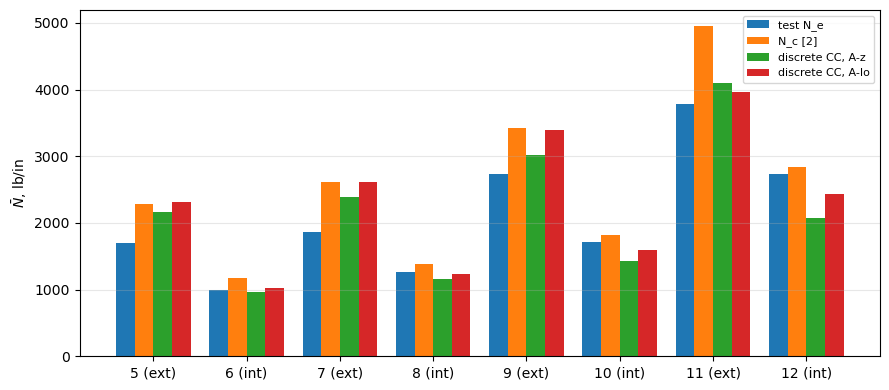

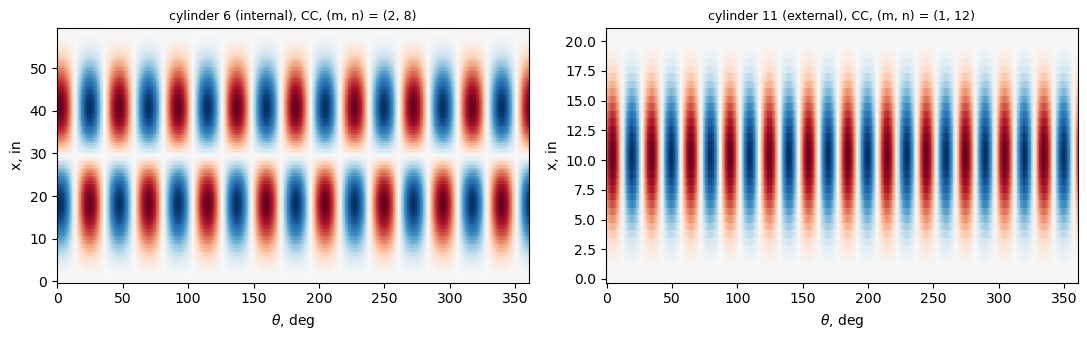

In [9]:
fig, ax = plt.subplots(figsize=(9, 4))
cs = list(CYL)
x = np.arange(len(cs))
vals = {'test N_e': [CYL[c][6] for c in cs], 'N_c [2]': [CYL[c][7] for c in cs],
        'discrete CC, A-z': [RES[(c, 'A-z', 'CC')][1][RES[(c, 'A-z', 'CC')][2]][0] for c in cs],
        'discrete CC, A-Io': [RES[(c, 'A-Io', 'CC')][1][RES[(c, 'A-Io', 'CC')][2]][0] for c in cs]}
for k, (name, v) in enumerate(vals.items()):
    ax.bar(x + (k - 1.5)*0.2, v, 0.2, label=name)
ax.set_xticks(x)
ax.set_xticklabels(['%d (%s)' % (c, CYL[c][0][:3]) for c in cs])
ax.set_ylabel(r'$\bar{N}$, lb/in')
ax.legend(fontsize=8)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, c in zip(axes, (6, 11)):
    model, out, n = RES[(c, 'A-z', 'CC')]
    w = normalize_phase(model.skin_field(out[n][2], W))
    th, wf = model.full_circumference(w, n)
    ax.pcolormesh(np.degrees(th), model.xlin, wf/np.abs(wf).max(), cmap='RdBu_r',
                  vmin=-1, vmax=1, shading='auto')
    ax.set_xlabel(r'$\theta$, deg')
    ax.set_ylabel('x, in')
    ax.set_title('cylinder %d (%s), CC, (m, n) = (%d, %d)' % (c, CYL[c][0], out[n][1], n), fontsize=9)
plt.tight_layout()
plt.show()

## Discussion

- **The Z section.** Read on the centre line of the sheet with the two bends,
  the nominal Z of [1] and [2] reproduces the smeared loads of Card and Jones
  within 0.4 % ($\bar{N}_c$) and 0.2 % ($\bar{N}_s$) for the eight cylinders,
  and $A_t$ within -1.2 to +2.3 %; with square corners the area is 5 %
  larger and the smeared loads 0.4 to 5.0 % higher. Card and Jones' section
  is therefore taken as this one.
- **Equivalent blades.** Replacing the Z by a blade changes the smeared load
  by -15.8 to +3.0 % (simply supported; up to -23.5 % clamped): the blade A-z
  (same area and centroid) has a much smaller moment of inertia, the blade
  A-Io (same bending stiffness about the skin) a centroid farther out. This
  section effect is larger than the discreteness effect, and it is why the
  gap is measured against the smeared theory of the same blade.
- **Discreteness gap.** Discrete model against the smeared theory of the same
  strip, general modes: simply supported -1.4 to -2.7 % (external) and -3.8
  to -6.6 % (internal), clamped -1.6 to -3.5 % (external) and -3.8 to -5.5 %
  (internal), and the two equivalent blades give the same gap within 0.4 %
  (1.1 % clamped). The gap does not depend on how the Z is approximated; it is
  larger for internal stringers. At 1.0 in spacing, the panels card1966
  notebook gives -6.6 % for the internal cylinder 4 against the strip as
  modelled.
- **Tests.** Card and Jones' tests are at 71 to 80 % (external) and 85 to 96 %
  (internal) of $\bar{N}_c$. Against the clamped discrete model with the blade
  A-Io, which reproduces $\bar{N}_c$ best for the external cylinders 5, 7, 9
  (-1.0 to +0.8 %), the model is 24 to 41 % above the external tests; for the
  internal cylinders (both blades 11 to 27 % below $\bar{N}_c$) it is -10.7
  to +3.5 % from the tests.
- **Local buckling.** The model leaves the whole pitch of 1.25 in of skin free
  between the blade roots; in the cylinders the riveted attached flange, 0.375
  in wide, covers 30 % of it. For the shortest external cylinder 11 the
  harmonic $n = 40$ (one half-wave per bay) gives 3424 lb/in, below the
  general mode of the blade A-z (4105 lb/in) and 9 % below the test (3780
  lb/in), which buckled in a general mode ($n_e = 8$): the local modes of the
  blade model are an artifact of the missing flange, and the clamped values
  of cylinder 11 (with the blade A-Io a mixed mode $(13, 20)$, 3963 lb/in)
  and of cylinder 9 (local 3373 lb/in, below the general mode of the blade
  A-Io) are lower bounds of the model, not of the cylinders.
- **The panels implementation of this case**
  (`panels/notebooks/peterson1959_blade_cylinder_buckling.ipynb`: half
  cylinder of Sanders skin panels and `plate_clpt_gl` blades, the same Z,
  blades and twisting stiffness, 18 x 8 x 5 terms) agrees within 0.6 % on the
  general modes, e.g. cylinder 6, blade A-z, clamped 966 and simply supported
  702 lb/in (here 968 and 703), cylinder 11, simply supported 1865 (here
  1871); its simply supported gaps are -1.6 to -2.8 % (external) and -4.0 to
  -6.7 % (internal). For cylinder 11 clamped it finds the local mode $(10,
  40)$ at 3482 lb/in (blade A-z; here $n = 40$: 3424), not converged with the
  number of terms, and for cylinder 9 with the blade A-Io a local mode at
  3233 lb/in.
- **Not modelled**: rivets (5/16 in pitch), the lap joints of the skin, the
  bends of the Z as plates, the unsymmetric bending of the Z (product of
  inertia), plasticity. A model of the Z by three plates (attached flange on
  the skin, web, free flange), like the channel stringers of the egle1968
  notebook, would remove the section and local-buckling approximations.